In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# =========================
# CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
#AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2.csv"
AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2_4class.csv"
TRANSLATED_CN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

RESULTS_DIR = "/content/drive/MyDrive/intent9Aug/context_ablation_previous_turn_plus_current_4class"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

print("Labels:", label2id)
print("LR:", LEARNING_RATE, "weight_decay:", WEIGHT_DECAY)

CONTEXT_CONDITION = "previous_turn_plus_current"
print("Context condition:", CONTEXT_CONDITION)


Labels: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
LR: 2e-05 weight_decay: 0.01
Context condition: previous_turn_plus_current


In [5]:
# =========================
# LOAD ORIGINAL ENGLISH DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Original full turn rows:", len(df_turns_full))
print("Original 4-class target rows:", len(target_df))
print("Original conversations:", target_df["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Original full turn rows: 5633
Original 4-class target rows: 3179
Original conversations: 825
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
# =========================
#  GROUPED SINGLE SPLIT
# =========================
gss1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df_original = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

train_cids = set(train_df_original["conversation_id"].astype(str))
val_cids = set(val_df["conversation_id"].astype(str))
test_cids = set(test_df["conversation_id"].astype(str))

print("Original train rows:", len(train_df_original))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Train ∩ Val:", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test:", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids)
assert train_cids.isdisjoint(test_cids)
assert val_cids.isdisjoint(test_cids)

#4class original english data split
assert len(train_df_original) == 2014, f"Unexpected train rows: {len(train_df_original)}"
assert len(val_df) == 503, f"Unexpected val rows: {len(val_df)}"
assert len(test_df) == 662, f"Unexpected test rows: {len(test_df)}"



Original train rows: 2014
Validation rows: 503
Test rows: 662
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [7]:
# =========================
# LLM AUGMENTATION TRAIN DATA ONLY
# =========================
aug_all_df = pd.read_csv(AUGMENTED_TRAIN_PATH)

required_aug_columns = {
    "conversation_id", "turn_index", "role", "text", "intent", "is_augmented"
}
missing_columns = required_aug_columns - set(aug_all_df.columns)
assert not missing_columns, f"Missing augmentation columns: {missing_columns}"

aug_all_df["conversation_id"] = aug_all_df["conversation_id"].astype(str)
aug_all_df["turn_index"] = pd.to_numeric(
    aug_all_df["turn_index"], errors="raise"
).astype(int)
aug_all_df["role"] = (
    aug_all_df["role"].fillna("").astype(str).str.strip().str.lower()
)
aug_all_df["text"] = aug_all_df["text"].fillna("").astype(str)
aug_all_df["intent"] = (
    aug_all_df["intent"].fillna("").astype(str).str.strip()
)

is_genuine_augmentation = (
    aug_all_df["is_augmented"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "1.0"])
)

aug_genuine_df = aug_all_df[
    is_genuine_augmentation
    & (aug_all_df["role"] == "user")
    & (aug_all_df["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

assert len(aug_genuine_df) > 0, (
    "No genuine augmented rows found. Check the is_augmented column."
)

#synthetic row may enter training only if its source English conversation is in the original train data
aug_train_df = aug_genuine_df[
    aug_genuine_df["conversation_id"].isin(train_cids)
].copy().reset_index(drop=True)

aug_cids = set(aug_train_df["conversation_id"].astype(str))

print("Rows in augmentation CSV:", len(aug_all_df))
print("Original/non-augmented rows excluded:", int((~is_genuine_augmentation).sum()))
print("valid 4-class augmentation rows:", len(aug_genuine_df))
print("Train-source genuine augmentation kept:", len(aug_train_df))
print("Valid augmentation rows excluded because source was not TRAIN:",
    len(aug_genuine_df) - len(aug_train_df),
)
print("Aug source ∩ Val:", len(aug_cids & val_cids))
print("Aug source ∩ Test:", len(aug_cids & test_cids))
print("Aug source outside Train:", len(aug_cids - train_cids))

assert aug_cids.isdisjoint(val_cids), (
    "LEAKAGE: validation-source augmentation entered training."
)
assert aug_cids.isdisjoint(test_cids), (
    "LEAKAGE: test-source augmentation entered training."
)
assert aug_cids.issubset(train_cids), (
    "Unexpected augmentation source outside original training split."
)

# Verify every synthetic row maps to an original 4-class TRAIN source turn
source_4class = train_df_original[
    ["conversation_id", "turn_index", "intent"]
].copy()
source_4class["conversation_id"] = source_4class["conversation_id"].astype(str)
source_4class["turn_index"] = source_4class["turn_index"].astype(int)

aug_source_check = aug_train_df.merge(
    source_4class,
    on=["conversation_id", "turn_index"],
    how="left",
    suffixes=("_aug", "_source"),
)

missing_source_turns = int(aug_source_check["intent_source"].isna().sum())
changed_labels = int((
    aug_source_check["intent_source"].notna()
    & (aug_source_check["intent_aug"] != aug_source_check["intent_source"])
).sum())

print("Augmented rows missing original TRAIN source turn:", missing_source_turns)
print("Augmented rows with changed labels:", changed_labels)

assert missing_source_turns == 0
assert changed_labels == 0

Rows in augmentation CSV: 2214
Original/non-augmented rows excluded: 2014
valid 4-class augmentation rows: 200
Train-source genuine augmentation kept: 200
Valid augmentation rows excluded because source was not TRAIN: 0
Aug source ∩ Val: 0
Aug source ∩ Test: 0
Aug source outside Train: 0
Augmented rows missing original TRAIN source turn: 0
Augmented rows with changed labels: 0


In [8]:
# =========================
# LOAD TRANSLATED CHINESE DATA — INDEPENDENT EXTERNAL TRAINING CORPUS so no removal
# =========================

with open(TRANSLATED_CN_PATH, "r", encoding="utf-8") as f:
    cn_raw = json.load(f)

cn_rows = []
for conv in cn_raw:
    cid = "CN_" + str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        cn_rows.append({
            "conversation_id": cid,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

cn_turns_full = pd.DataFrame(cn_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)
cn_turns_full["conversation_id"] = cn_turns_full["conversation_id"].astype(str)
cn_turns_full["turn_index"] = cn_turns_full["turn_index"].astype(int)
cn_turns_full["role"] = cn_turns_full["role"].astype(str).str.lower()
cn_turns_full["text"] = cn_turns_full["text"].fillna("").astype(str)

cn_train_df = cn_turns_full[
    (cn_turns_full["role"] == "user") &
    (cn_turns_full["intent"].notna()) &
    (cn_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Independent translated CN 4-class rows retained:", len(cn_train_df))
print("CN rows removed:", 0)

cn_turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in cn_turns_full.groupby("conversation_id")
}
turns_by_conv_full.update(cn_turns_by_conv_full)


Independent translated CN 4-class rows retained: 3055
CN rows removed: 0


In [9]:
# =========================
# FINAL TRAIN + LEAKAGE AUDIT
# =========================
# translated CN is an independent training data so used all no filter
train_df = pd.concat(
    [train_df_original, aug_train_df, cn_train_df],
    ignore_index=True,
).reset_index(drop=True)

print("Final train rows:", len(train_df))
print("  original English:", len(train_df_original))
print("  genuine safe augmentation:", len(aug_train_df))
print("  independent translated CN:", len(cn_train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nFinal train label distribution:")
print(train_df["intent"].value_counts())

missing_context_cids = (
    set(train_df["conversation_id"].astype(str)) - set(turns_by_conv_full.keys())
)
print("Missing context conversation IDs:", len(missing_context_cids))
assert len(missing_context_cids) == 0

audit = pd.DataFrame([{
    "original_train_rows": len(train_df_original),
    "augmentation_csv_rows": len(aug_all_df),
    "genuine_4class_aug_rows": len(aug_genuine_df),
    "safe_train_source_aug_rows": len(aug_train_df),
    "genuine_aug_rows_excluded_nontrain_source": len(aug_genuine_df) - len(aug_train_df),
    "independent_cn_rows": len(cn_train_df),
    "cn_rows_removed": 0,
    "final_train_rows": len(train_df),
    "val_rows": len(val_df),
    "test_rows": len(test_df),
    "train_val_cid_overlap": len(train_cids & val_cids),
    "train_test_cid_overlap": len(train_cids & test_cids),
    "val_test_cid_overlap": len(val_cids & test_cids),
    "aug_val_source_overlap": len(aug_cids & val_cids),
    "aug_test_source_overlap": len(aug_cids & test_cids),
    "aug_missing_source_turns": missing_source_turns,
    "aug_changed_labels": changed_labels,
}])

audit.to_csv(os.path.join(RESULTS_DIR, "leakage_audit.csv"), index=False)
display(audit)


Final train rows: 5269
  original English: 2014
  genuine safe augmentation: 200
  independent translated CN: 3055
Validation rows: 503
Test rows: 662

Final train label distribution:
intent
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64
Missing context conversation IDs: 0


,original_train_rows,augmentation_csv_rows,genuine_4class_aug_rows,safe_train_source_aug_rows,genuine_aug_rows_excluded_nontrain_source,independent_cn_rows,cn_rows_removed,final_train_rows,val_rows,test_rows,train_val_cid_overlap,train_test_cid_overlap,val_test_cid_overlap,aug_val_source_overlap,aug_test_source_overlap,aug_missing_source_turns,aug_changed_labels
0,2014,2214,200,200,0,3055,0,5269,503,662,0,0,0,0,0,0,0


In [16]:
# ============================================================
# CONTEXT ABLATION 2
# PREVIOUS DIALOGUE TURN + CURRENT USER UTTERANCE
# ============================================================
# IMPORTANT: this is the ONLY methodological change relative to the
# full-context run. Dataset membership, augmentation, translated data,
# labels, weights, model, seed, and hyperparameters remain unchanged.


def build_previous_turn_plus_current_dataset(df_split, turns_by_conv):
    """
    Controlled context-ablation condition:
    immediately previous dialogue turn + current target user utterance.

    For synthetic rows, the current utterance comes from row["text"], while
    the previous turn is recovered from the source conversation using the
    retained conversation_id / turn_index provenance.
    """
    X, y = [], []

    for _, row in df_split.iterrows():
        cid = str(row["conversation_id"])
        ti = int(row["turn_index"])

        assert cid in turns_by_conv, f"Missing conversation for {cid}"

        turns = turns_by_conv[cid].sort_values("turn_index").reset_index(drop=True)

        current_text = str(row["text"]).strip()
        assert current_text != "", f"Empty current target text: {cid} / turn {ti}"

        pieces = []

        # Use only the immediately preceding dialogue turn, if present.
        prev_turns = turns[turns["turn_index"] < ti]
        if len(prev_turns) > 0:
            previous_turn = prev_turns.iloc[-1]
            prev_role = str(previous_turn["role"]).strip().upper()
            prev_text = str(previous_turn["text"]).strip()

            if prev_text:
                pieces.append(f"{prev_role}: {prev_text}")

        pieces.append(f"USER: {current_text}")

        X.append("\n".join(pieces))
        y.append(str(row["intent"]))

    return np.array(X), np.array(y)


X_train, y_train = build_previous_turn_plus_current_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_previous_turn_plus_current_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_previous_turn_plus_current_dataset(test_df, turns_by_conv_full)

print("PREVIOUS-TURN + CURRENT train:", len(X_train))
print("PREVIOUS-TURN + CURRENT val:", len(X_val))
print("PREVIOUS-TURN + CURRENT test:", len(X_test))

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())
print("\nValidation distribution:")
print(pd.Series(y_val).value_counts())
print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# ------------------------------------------------------------
# SANITY CHECKS: representation changed, dataset did not
# ------------------------------------------------------------
assert len(X_train) == len(train_df)
assert len(X_val) == len(val_df)
assert len(X_test) == len(test_df)
assert len(y_train) == len(train_df)
assert len(y_val) == len(val_df)
assert len(y_test) == len(test_df)

assert all("USER:" in str(x) for x in X_train)
assert all("USER:" in str(x) for x in X_val)
assert all("USER:" in str(x) for x in X_test)

# Verify each constructed input contains its own current target text.
for x, (_, row) in zip(X_train, train_df.iterrows()):
    assert str(row["text"]).strip() in str(x)

for x, (_, row) in zip(X_val, val_df.iterrows()):
    assert str(row["text"]).strip() in str(x)

for x, (_, row) in zip(X_test, test_df.iterrows()):
    assert str(row["text"]).strip() in str(x)

# Most examples should include some previous context.
assert any(str(x).startswith("SYSTEM:") or str(x).startswith("USER:") and "\nUSER:" in str(x) for x in X_train)

print(
    "\nPASS: previous-turn + current ablation built correctly; "
    "train/val/test membership and example counts are unchanged."
)

print("\nExample previous-turn + current model input:")
print(X_train[1])

PREVIOUS-TURN + CURRENT train: 5269
PREVIOUS-TURN + CURRENT val: 503
PREVIOUS-TURN + CURRENT test: 662

Train distribution:
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64

Validation distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

PASS: previous-turn + current ablation built correctly; train/val/test membership and example counts are unchanged.

Example previous-turn + current model input:
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [17]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))



--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [18]:
print("Example previous-turn + current model input:")
print(X_train[1])
assert "USER:" in X_train[1]
assert X_train[1].count("\n") <= 1


Example previous-turn + current model input:
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [19]:
# =========================
# LABEL IDS + DISTRIBUTION + TRAIN-ONLY CLASS WEIGHTS
# =========================
y_train_ids = np.array([label2id[x] for x in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[x] for x in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[x] for x in y_test], dtype=np.int64)

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist,
}).reindex(VALID_LABELS).fillna(0)

print("Label distribution (%):")
print(dist_df)

classes = np.arange(len(VALID_LABELS))
missing = set(classes) - set(np.unique(y_train_ids))
assert not missing, f"Missing train classes: {[id2label[i] for i in sorted(missing)]}"

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("\nClass weights:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {id2label[cls_id]}: {w:.4f}")

Label distribution (%):
            train_%     val_%    test_%
Chitchat   0.104574  0.075547  0.081571
Interpret  0.516227  0.580517  0.590634
Reveal     0.312773  0.320080  0.297583
Revise     0.066426  0.023857  0.030211

Class weights:
  Chitchat: 2.3907
  Interpret: 0.4843
  Reveal: 0.7993
  Revise: 3.7636


In [20]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        labels=np.arange(len(VALID_LABELS)),
        average="macro",
        zero_division=0,
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [21]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [22]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        digits=3,
        zero_division=0,
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    # Compact numeric metrics for paper tables
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="weighted",
        zero_division=0,
    )

    acc = accuracy_score(y_true, y_pred)

    _, _, per_class_f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average=None,
        zero_division=0,
    )

    metrics = {
        "split": split_name.upper(),
        "model": model_name,
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "samples": len(y_true),
    }

    for label, f1_val, supp in zip(VALID_LABELS, per_class_f1, support):
        metrics[f"{label.lower()}_f1"] = f1_val
        metrics[f"{label.lower()}_support"] = supp

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS,
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred,
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False,
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False,
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False,
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8",
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        f.write("\n\n=== COMPACT METRICS ===\n")
        f.write(pd.DataFrame([metrics]).to_string(index=False))

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors, metrics


print("All helpers defined.")

All helpers defined.


In [23]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=NUM_EPOCHS):
    """
    1. Tokenize with the model's own tokenizer.
    2. Train with WeightedTrainer using TRAIN data.
    3. Select best checkpoint using VAL macro-F1.
    4. Plot learning curve.
    5. Evaluate on TRAIN, VAL, and TEST.
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)

    set_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train,
        y_train_ids,
        X_val,
        y_val_ids,
        X_test,
        y_test_ids,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    short_name = model_name.split("/")[-1]
    output_dir = os.path.join(RESULTS_DIR, f"{short_name}_results")

    training_args = TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
        save_total_limit=2,
    )

    trainer = WeightedTrainer(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation
    _, _, _, _, train_metrics = evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation
    _, _, _, _, val_metrics = evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    _, _, _, _, test_metrics = evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    all_metrics_df = pd.DataFrame([train_metrics, val_metrics, test_metrics])
    all_metrics_path = os.path.join(
        RESULTS_DIR,
        f"{short_name}_all_split_metrics.csv",
    )
    all_metrics_df.to_csv(all_metrics_path, index=False)

    print("\n=== Compact metrics summary ===")
    display(all_metrics_df)
    print(f"Saved metrics summary: {all_metrics_path}")

    return trainer, test_metrics


print("run_model() defined.")

run_model() defined.


## DistilBERT — skipped for controlled context ablation

In [ ]:
print("SKIP DistilBERT — context ablation uses BERT-base only.")

## RoBERTa-base — skipped for controlled context ablation

In [ ]:
print("SKIP RoBERTa — context ablation uses BERT-base only.")

## BERT-base-uncased — context ablation model


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/context_ablation_previous_turn_plus_current_4class/bert-base-uncased_results/checkpoint-2636
Best validation macro-F1: 0.6477269474386037


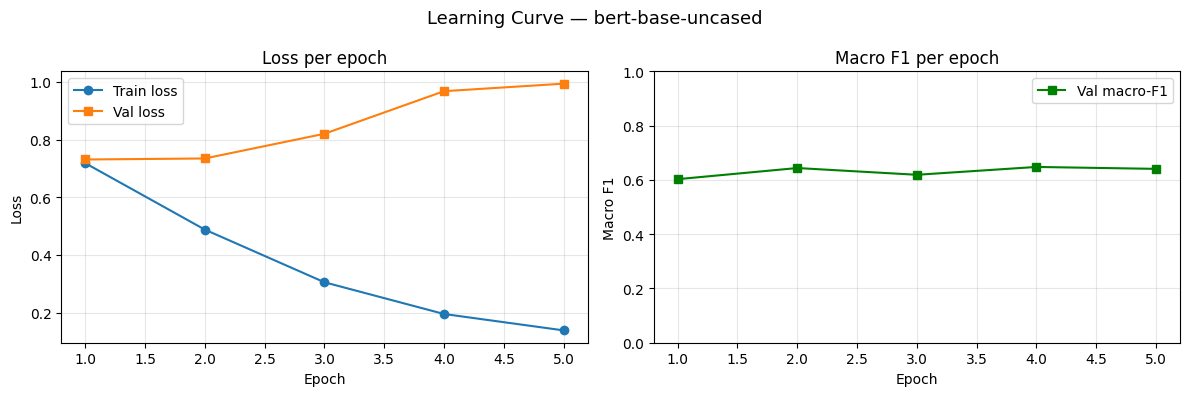

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.942     0.973     0.957       551
   Interpret      0.983     0.985     0.984      2720
      Reveal      0.984     0.964     0.974      1648
      Revise      0.947     0.977     0.962       350

    accuracy                          0.977      5269
   macro avg      0.964     0.975     0.969      5269
weighted avg      0.977     0.977     0.977      5269


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             536               8            7            0
true_Interpret              8            2679           16           17
true_Reveal                25              32         1589            2
true_Revise                 0               5            3          342


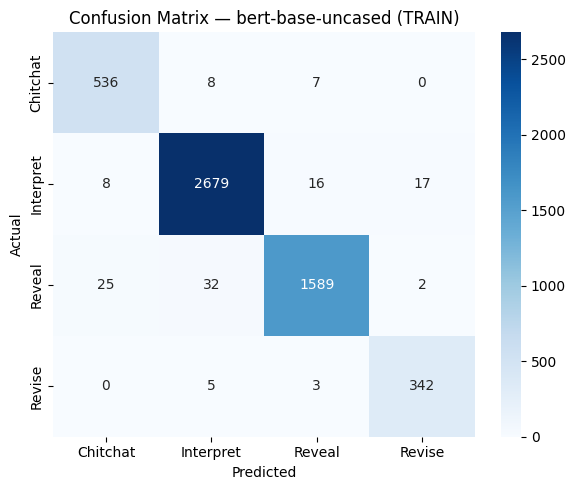


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.707     0.763     0.734        38
   Interpret      0.887     0.856     0.871       292
      Reveal      0.819     0.845     0.832       161
      Revise      0.143     0.167     0.154        12

    accuracy                          0.829       503
   macro avg      0.639     0.658     0.648       503
weighted avg      0.834     0.829     0.831       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              29               5            4            0
true_Interpret              8             250           24           10
true_Reveal                 4              19          136            2
true_Revise                 0               8            2            2


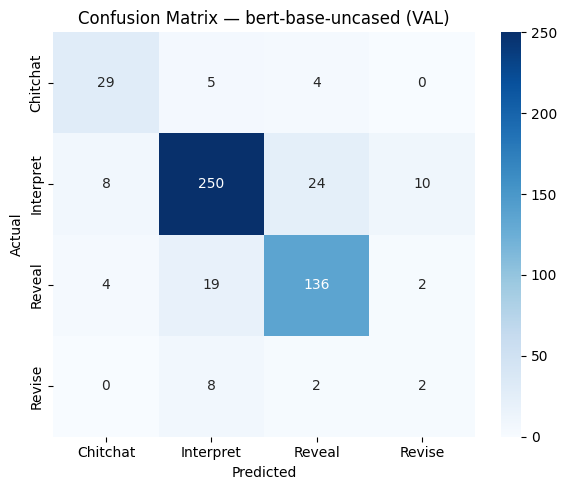


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,24
1,Reveal,Interpret,19
2,Interpret,Revise,10
3,Interpret,Chitchat,8
4,Revise,Interpret,8
5,Chitchat,Interpret,5
6,Chitchat,Reveal,4
7,Reveal,Chitchat,4
8,Reveal,Revise,2
9,Revise,Reveal,2



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,SYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,SYSTEM: How about this?\nUSER: I want a mounta...,Revise,Interpret
8,SYSTEM: Is this plain colour okay?\nUSER: I wa...,Reveal,Revise
9,"SYSTEM: Do you want this?\nUSER: OK, thanks.",Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,SYSTEM: Hi，how can ihelp u\nUSER: Show me some...,Reveal,Revise
19,SYSTEM: Sure!\nUSER: ok tks,Interpret,Chitchat
21,SYSTEM: What size of phone do you want，and wha...,Interpret,Reveal
23,SYSTEM: What sboput these ones?\nUSER: Yes 'I ...,Interpret,Revise
31,SYSTEM: what kinds of photo ?\nUSER: with my f...,Interpret,Reveal



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.731     0.704     0.717        54
   Interpret      0.885     0.885     0.885       391
      Reveal      0.817     0.838     0.827       197
      Revise      0.176     0.150     0.162        20

    accuracy                          0.834       662
   macro avg      0.652     0.644     0.648       662
weighted avg      0.831     0.834     0.832       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              38              11            5            0
true_Interpret              6             346           26           13
true_Reveal                 7              24          165            1
true_Revise                 1              10            6            3


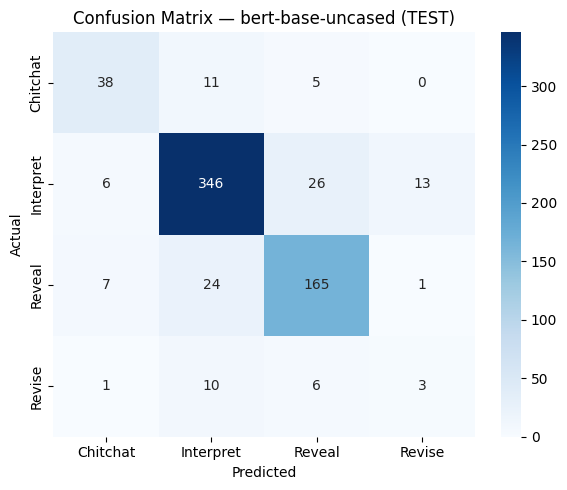


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,26
1,Reveal,Interpret,24
2,Interpret,Revise,13
3,Chitchat,Interpret,11
4,Revise,Interpret,10
5,Reveal,Chitchat,7
6,Interpret,Chitchat,6
7,Revise,Reveal,6
8,Chitchat,Reveal,5
9,Revise,Chitchat,1



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"SYSTEM: Okay, here are some bigger models\nUSE...",Reveal,Interpret
11,"SYSTEM: this is very nice, do you like it?\nUS...",Reveal,Chitchat
14,SYSTEM: how about this?\nUSER: OK,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,SYSTEM: Got it! Do you have a specific budget ...,Revise,Interpret
23,SYSTEM: Here are two excellent options for you...,Revise,Interpret
27,SYSTEM: Do you prefer a specific design or bra...,Revise,Interpret
32,"SYSTEM: ok, any prefer smells?\nUSER: Do you h...",Interpret,Revise
33,SYSTEM: Sure\nUSER: Looks good,Interpret,Chitchat
38,SYSTEM: Could you please share your budget and...,Reveal,Interpret



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,bert-base-uncased,0.976656,0.964188,0.974761,0.969330,0.976876,0.976656,0.976693,5269,0.957143,551,0.984203,2720,0.973950,1648,0.962025,350
1,VAL,bert-base-uncased,0.829026,0.638994,0.657677,0.647727,0.833720,0.829026,0.831055,503,0.734177,38,0.871080,292,0.831804,161,0.153846,12
2,TEST,bert-base-uncased,0.833837,0.652245,0.644044,0.647780,0.830675,0.833837,0.832164,662,0.716981,54,0.884910,391,0.827068,197,0.162162,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/context_ablation_previous_turn_plus_current_4class/bert-base-uncased_all_split_metrics.csv


,Context,Model,Seed,Accuracy,Macro_F1,Weighted_F1,Chitchat_F1,Interpret_F1,Reveal_F1,Revise_F1,Test_samples
0,Previous turn + current utterance,BERT-base,42,0.833837,0.64778,0.832164,0.716981,0.88491,0.827068,0.162162,662


Saved manuscript-ready context-ablation row.


In [24]:
bert_trainer, bert_test_metrics = run_model(
    "bert-base-uncased",
    num_epochs=NUM_EPOCHS,
)

# Save one manuscript-ready row for the context-ablation table.
context_result = pd.DataFrame([{
    "Context": "Previous turn + current utterance",
    "Model": "BERT-base",
    "Seed": RANDOM_STATE,
    "Accuracy": bert_test_metrics["accuracy"],
    "Macro_F1": bert_test_metrics["macro_f1"],
    "Weighted_F1": bert_test_metrics["weighted_f1"],
    "Chitchat_F1": bert_test_metrics.get("chitchat_f1"),
    "Interpret_F1": bert_test_metrics.get("interpret_f1"),
    "Reveal_F1": bert_test_metrics.get("reveal_f1"),
    "Revise_F1": bert_test_metrics.get("revise_f1"),
    "Test_samples": bert_test_metrics["samples"],
}])

display(context_result)
context_result.to_csv(
    os.path.join(RESULTS_DIR, "context_ablation_previous_turn_plus_current_result.csv"),
    index=False,
)
print("Saved manuscript-ready context-ablation row.")


## MiniLM — skipped for controlled context ablation

In [ ]:
print("SKIP MiniLM — context ablation uses BERT-base only.")